# Análisis temporal del error de pronóstico

`3_analisis_temporal.ipynb` corrió ACF, PACF y tests de estacionariedad (ADF/KPSS) sobre `obs_temp_c` -la temperatura
observada-, no sobre `error_temp_c = fcst_temp_c - obs_temp_c`, que es lo que un modelo de corrección va a tener que
predecir en realidad. El pronóstico ya captura buena parte del ciclo diurno y estacional de la temperatura, así que
el error resultante puede tener una dinámica temporal completamente distinta a la de la temperatura cruda -las
conclusiones de la notebook 3 no se trasladan automáticamente.

Esta notebook repite el mismo tipo de diagnóstico que `3_analisis_temporal.ipynb` (cohorte por intermitencia,
imputación acotada, ADF/KPSS, ACF/PACF) pero sobre `error_temp_c`, partiendo de **`dataset_modelado.csv`** (salida de
`5_separacion_train_test.ipynb`) en vez de recalcularlo desde `mediciones_limpias.csv`.

Esto corrige una versión anterior de esta notebook que recalculaba `error_temp_c` directamente desde
`mediciones_limpias.csv` -la misma fuente que usa la notebook 3-, usando el error **previo al fix** de la notebook 5
(calculado contra el `obs_temp_c` *crudo*, antes de que `3_analisis_temporal.ipynb` corrigiera saltos horarios
imposibles e imputara huecos cortos; ver sección 2 de `5_separacion_train_test.ipynb`). Esa versión anterior tenía
dos problemas: (1) describía la dinámica de una serie de error distinta a la que realmente se usa como target en
`dataset_modelado.csv`, y (2) al mergear sus features con las de la notebook 5 en `7_interpretabilidad.ipynb`, el
choque de nombres de columna (`error_temp_c` presente en ambos lados del merge) hacía que el modelo se entrenara
contra *esta* versión vieja del error sin que se notara. Partir acá de `dataset_modelado.csv` elimina la ambigüedad:
hay una sola definición de `error_temp_c` en todo el pipeline.

La consecuencia práctica es que el cohorte de estaciones ya no se recalcula sobre el universo completo de 498
estaciones del proyecto, sino sobre las 466 que `3_analisis_temporal.ipynb` ya seleccionó por intermitencia de
`obs_temp_c` (`panel_features.csv`, el insumo de `dataset_modelado.csv`) -es el único universo disponible en esta
fuente. Dentro de esas 466, esta notebook sigue aplicando su propio criterio de intermitencia, ahora sobre
`error_temp_c` ya bien definido: una estación puede tener la temperatura bien cubierta y el error (que depende
también de la disponibilidad del pronóstico) más gappy, o viceversa, así que ese segundo filtro conserva sentido.

Con el diagnóstico hecho (secciones 1-8), la notebook cierra armando el dataset de features sobre `error_temp_c`
(sección 9) -lags, rolling, dirección de viento cíclica, vecinas-, anclado en `shift(HORIZONTE)` = `shift(6)` para
respetar el horizonte de 6h del pronóstico. No modifica el pipeline de datos ni las notebooks anteriores: es un
complemento de diagnóstico y feature engineering, autocontenido salvo por depender de `dataset_modelado.csv`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf as acf_statsmodels, adfuller, kpss
from utils import AZUL, NARANJA, GRIS_TEXTO, aplicar_estilo

PROCESSED = '../data/processed/'
OUT = '../data/out/temporal_error/'

aplicar_estilo()
figuras = {}  # se exportan todas al final

## 1. Carga

`dataset_modelado.csv` (salida de `5_separacion_train_test.ipynb`) trae `error_temp_c` ya recalculado contra el
`obs_temp_c` corregido -saltos horarios imposibles filtrados, huecos cortos imputados (`3_analisis_temporal.ipynb`)-,
además de `obs_wind_direction_d` y las coordenadas en la misma fila, así que no hace falta ningún merge adicional
acá. El único dato que no trae es `horizonte_horas` -se verifica una vez más contra `mediciones_limpias.csv` (ya
confirmado en 6h por `5_separacion_train_test.ipynb`), porque la selección de lags de las próximas secciones depende
de ese valor.

In [2]:
horizonte_horas = pd.read_csv(PROCESSED + 'mediciones_limpias.csv', usecols=['horizonte_horas'])['horizonte_horas']
assert horizonte_horas.nunique() == 1, 'hay más de un horizonte de pronóstico en mediciones_limpias.csv'
HORIZONTE = int(horizonte_horas.iloc[0])

df = pd.read_csv(PROCESSED + 'dataset_modelado.csv',
                  usecols=['station_id', 'target_hour_utc', 'error_temp_c',
                           'obs_wind_direction_d', 'estado', 'red', 'latitud', 'longitud'])
df['target_hour_utc'] = pd.to_datetime(df['target_hour_utc'], utc=True)
df = df.sort_values(['station_id', 'target_hour_utc']).reset_index(drop=True)

RANGO_COMPLETO = pd.date_range(df['target_hour_utc'].min(), df['target_hour_utc'].max(), freq='h')
print(f'{len(df):,} filas, {df.station_id.nunique()} estaciones, horizonte = {HORIZONTE}h')
print(f'Rango del proyecto: {RANGO_COMPLETO.min()} a {RANGO_COMPLETO.max()} ({len(RANGO_COMPLETO)} horas)')
print(f'{100 * df["error_temp_c"].notna().mean():.1f}% de las filas existentes con error resuelto')

165,896 filas, 466 estaciones, horizonte = 6h
Rango del proyecto: 2026-10-19 02:00:00+00:00 a 2026-11-02 21:00:00+00:00 (356 horas)
73.9% de las filas existentes con error resuelto


## 2. Cobertura e intermitencia por estación

Mismo criterio que `3_analisis_temporal.ipynb`: `UMBRAL_HUECO = 12h` separa la intermitencia "normal" de estación del
salto al apagón compartido (~120h). Se mide el hueco más largo de `error_temp_c` por estación -no el de `obs_temp_c`,
que es lo que midió la notebook 3- sobre las 466 estaciones disponibles en `dataset_modelado.csv` (el universo ya
quedó acotado por la notebook 3 al armar `panel_features.csv`; acá no se vuelve a ampliar a las 498 del proyecto).

In [3]:
UMBRAL_HUECO = 12

df_error = df.dropna(subset=['error_temp_c'])


def resumen_cobertura(g):
    huecos = g['target_hour_utc'].diff().dt.total_seconds().div(3600).dropna()
    return pd.Series({
        'n_horas': len(g),
        'cobertura_pct': 100 * len(g) / len(RANGO_COMPLETO),
        'hueco_max_h': huecos.max() if len(huecos) else np.nan,
    })


cobertura = df_error.groupby('station_id').apply(resumen_cobertura, include_groups=False)
atributos_estacion = df.groupby('station_id')[['estado', 'red', 'latitud', 'longitud']].first()
cobertura = cobertura.join(atributos_estacion)
cobertura['hueco_max_h'].describe()

count    466.000000
mean      44.487124
std       52.037092
min        5.000000
25%       11.000000
50%       11.000000
75%      120.000000
max      304.000000
Name: hueco_max_h, dtype: float64

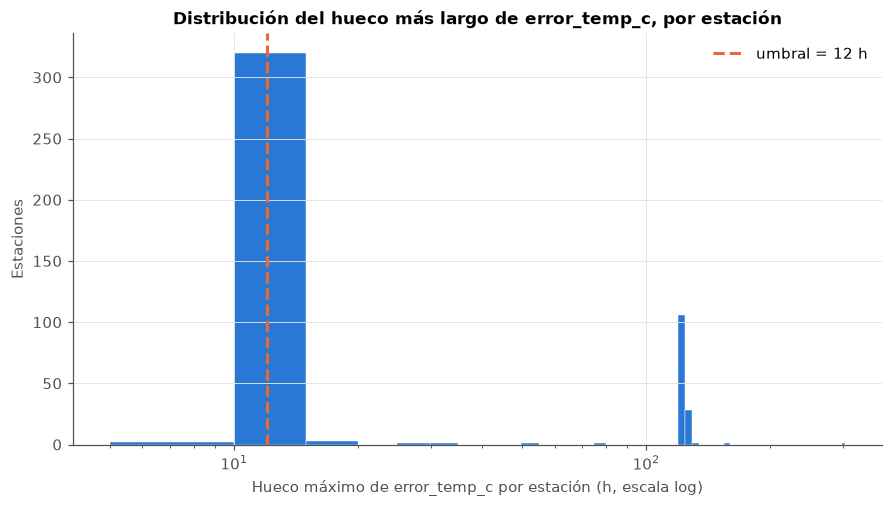

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.hist(cobertura['hueco_max_h'], bins=60, color=AZUL, edgecolor='white', linewidth=0.3)
ax.axvline(UMBRAL_HUECO, color=NARANJA, lw=2, ls='--', label=f'umbral = {UMBRAL_HUECO} h')
ax.set(xscale='log', xlabel='Hueco máximo de error_temp_c por estación (h, escala log)', ylabel='Estaciones',
       title='Distribución del hueco más largo de error_temp_c, por estación')
ax.legend(frameon=False)
figuras['01_huecos_por_estacion'] = fig
plt.show()

## 3. El apagón compartido (22-27/10): se excluye del criterio de admisión, no se imputa

Igual que en la notebook 3: si el único hueco largo de una estación es la ventana del apagón, no tiene sentido
descartarla del cohorte por eso -se mide el hueco máximo *excluyendo* esa ventana para decidir quién entra, pero la
ventana en sí queda como `NaN` sin completar (es más larga que `UMBRAL_HUECO`, imputarla sería inventar 5 días de
error que nunca se resolvió).

In [5]:
INICIO_CORTE = pd.Timestamp('2026-10-22', tz='UTC')
FIN_CORTE = pd.Timestamp('2026-10-27', tz='UTC')


def hueco_max_sin_corte(g):
    t = g['target_hour_utc'].reset_index(drop=True)
    inicios, fines = t[:-1].reset_index(drop=True), t[1:].reset_index(drop=True)
    huecos_h = (fines - inicios).dt.total_seconds().div(3600)
    solapa_corte = (inicios < FIN_CORTE) & (fines > INICIO_CORTE)
    restantes = huecos_h[~solapa_corte]
    return restantes.max() if len(restantes) else np.nan


cobertura['hueco_max_h_sin_corte'] = df_error.groupby('station_id').apply(hueco_max_sin_corte, include_groups=False)

recuperadas = cobertura[(cobertura['hueco_max_h'] > UMBRAL_HUECO) & (cobertura['hueco_max_h_sin_corte'] <= UMBRAL_HUECO)]
print(f'{len(recuperadas)} estaciones cuyo único hueco largo en error_temp_c era el corte compartido -se reincorporan al cohorte')
print()
siguen_fuera = cobertura[cobertura['hueco_max_h_sin_corte'] > UMBRAL_HUECO]
print(f'{len(siguen_fuera)} estaciones con intermitencia propia en error_temp_c -siguen fuera del cohorte')
print(siguen_fuera['hueco_max_h_sin_corte'].describe())

142 estaciones cuyo único hueco largo en error_temp_c era el corte compartido -se reincorporan al cohorte

2 estaciones con intermitencia propia en error_temp_c -siguen fuera del cohorte
count     2.000000
mean     65.500000
std      19.091883
min      52.000000
25%      58.750000
50%      65.500000
75%      72.250000
max      79.000000
Name: hueco_max_h_sin_corte, dtype: float64


## 4. Cohorte de estaciones (sobre `error_temp_c`, no sobre `obs_temp_c`)

In [6]:
cohorte = cobertura[cobertura['hueco_max_h_sin_corte'] <= UMBRAL_HUECO].index

print(f'Estaciones en el cohorte: {len(cohorte)} de {len(cobertura)} ({len(cohorte) / len(cobertura):.1%})')
print(f'Cobertura media del cohorte: {cobertura.loc[cohorte, "cobertura_pct"].mean():.1f}%')
print()
print('Redes excluidas (fuera del cohorte), top 8:')
print(cobertura.loc[~cobertura.index.isin(cohorte), 'red'].value_counts().head(8))

Estaciones en el cohorte: 464 de 466 (99.6%)
Cobertura media del cohorte: 73.9%

Redes excluidas (fuera del cohorte), top 8:
red
OTHER-MTR    1
ASOS-HFM     1
Name: count, dtype: int64


## 5. Regularización horaria + imputación acotada

A diferencia de la versión anterior de esta notebook (que partía de `mediciones_limpias.csv`, sparse), acá no hace
falta reindexar: `dataset_modelado.csv` ya viene con una fila por estación y hora para las 466 del cohorte de
`panel_features.csv` -es la salida de un `reindex` que ya hizo `3_analisis_temporal.ipynb`-, así que sólo se filtra
al cohorte de la sección 4 y se ordena. Lo que sigue haciendo falta es interpolar sólo los huecos cortos (≤12h,
`LIMITE_IMPUTACION = UMBRAL_HUECO`) de `error_temp_c` dentro de esa grilla ya completa -interpolación lineal, no
`ffill`, para no dejar al error "pegado" en un valor plano durante el hueco: `ffill` introduciría tramos constantes
artificiales que inflarían la autocorrelación de corto plazo mucho más que una recta entre dos puntos reales, justo
el tipo de distorsión que se audita en la sección 6. El apagón largo queda sin completar y marcado como faltante
-no imputado- vía el flag `error_temp_c_imputado`.

In [7]:
panel = df.loc[df['station_id'].isin(cohorte), ['station_id', 'target_hour_utc', 'error_temp_c', 'obs_wind_direction_d']].copy()
panel = panel.sort_values(['station_id', 'target_hour_utc']).reset_index(drop=True)

assert len(panel) == len(cohorte) * len(RANGO_COMPLETO), 'dataset_modelado.csv no viene regularizado como se esperaba'
print(f'Panel: {panel.shape[0]:,} filas ({len(cohorte)} estaciones x {len(RANGO_COMPLETO)} horas)')
print(f'{100 * panel["error_temp_c"].isna().mean():.1f}% faltante (antes de imputar huecos cortos)')

Panel: 165,184 filas (464 estaciones x 356 horas)
26.1% faltante (antes de imputar huecos cortos)


In [8]:
LIMITE_IMPUTACION = UMBRAL_HUECO

panel['error_temp_c_imputado'] = panel['error_temp_c'].isna()
panel['error_temp_c'] = panel.groupby('station_id')['error_temp_c'].transform(
    lambda s: s.interpolate(method='linear', limit=LIMITE_IMPUTACION, limit_area='inside'))
panel['error_temp_c_imputado'] &= panel['error_temp_c'].notna()

print(f'{100 * panel["error_temp_c"].isna().mean():.1f}% sigue faltante tras imputar huecos cortos (apagón + bordes de estación)')
print(f'{100 * panel["error_temp_c_imputado"].mean():.1f}% de las filas del panel son un hueco corto imputado')

10.4% sigue faltante tras imputar huecos cortos (apagón + bordes de estación)
15.7% de las filas del panel son un hueco corto imputado


### Estaciones sin ningún faltante remanente

ADF y KPSS necesitan una serie completa, sin `NaN`. Las estaciones que sufrieron el apagón todavía tienen ese bloque
sin completar -no entran a los tests de estacionariedad, pero sí quedan contempladas en la cobertura del cohorte de
arriba. Esto es exactamente lo que hace `3_analisis_temporal.ipynb` con `obs_temp_c` (ahí 324 de 466 quedan con cero
faltante remanente).

In [9]:
pct_faltante = panel.groupby('station_id')['error_temp_c'].apply(lambda s: s.isna().mean() * 100)
candidatas = pct_faltante[pct_faltante == 0].to_frame('pct_faltante').join(atributos_estacion)

print(f'{len(candidatas)} de {len(cohorte)} estaciones del cohorte sin ningún faltante remanente en error_temp_c')

ESTACIONES_EJEMPLO = candidatas.sort_values('pct_faltante').drop_duplicates('estado').head(3).index.tolist()
candidatas.loc[ESTACIONES_EJEMPLO]

125 de 464 estaciones del cohorte sin ningún faltante remanente en error_temp_c


,pct_faltante,estado,red,latitud,longitud
station_id,,,,,
KABI,0.0,TX,ASOS-HFM,32.41028,-99.68167
KABR,0.0,SD,ASOS-HFM,45.44333,-98.41306
KAEX,0.0,LA,ASOS-HFM,31.33472,-92.55861


## 6. ACF ingenuo vs. pares reales: ¿infla la imputación la autocorrelación del error?

Se compara el ACF calculado sobre el panel ya imputado (el único que puede alimentar a ADF/KPSS) contra un ACF que
sólo usa pares de valores **reales** en cada lag -mismo chequeo que hace la notebook 3 con `obs_temp_c`.

In [10]:
NLAGS = 48


def acf_pares_completos(valores, es_imputado, nlags):
    real = pd.Series(valores).where(~pd.Series(es_imputado).to_numpy())
    salida = []
    for k in range(nlags + 1):
        x, y = real, real.shift(k)
        validos = x.notna() & y.notna()
        salida.append(x[validos].corr(y[validos]) if validos.sum() > 2 else np.nan)
    return np.array(salida)


comparacion = []
for sid in ESTACIONES_EJEMPLO:
    d = panel[panel['station_id'] == sid].sort_values('target_hour_utc')
    ingenuo = acf_statsmodels(d['error_temp_c'], nlags=NLAGS, fft=True)
    reales = acf_pares_completos(d['error_temp_c'].values, d['error_temp_c_imputado'].values, NLAGS)
    comparacion.append(pd.DataFrame({'station_id': sid, 'lag': range(NLAGS + 1),
                                      'ACF ingenuo': ingenuo, 'ACF pares reales': reales}))

tabla_comparacion = pd.concat(comparacion).set_index(['station_id', 'lag']).sort_index()
tabla_comparacion['diferencia_abs'] = (tabla_comparacion['ACF ingenuo'] - tabla_comparacion['ACF pares reales']).abs()

print('Diferencia absoluta ACF ingenuo vs. pares reales, por estación (lags 1-24):')
print(tabla_comparacion.loc[(slice(None), slice(1, 24)), 'diferencia_abs'].groupby('station_id').agg(['mean', 'max']).round(3))

Diferencia absoluta ACF ingenuo vs. pares reales, por estación (lags 1-24):
             mean    max
station_id              
KABI        0.027  0.098
KABR        0.028  0.053
KAEX        0.048  0.142


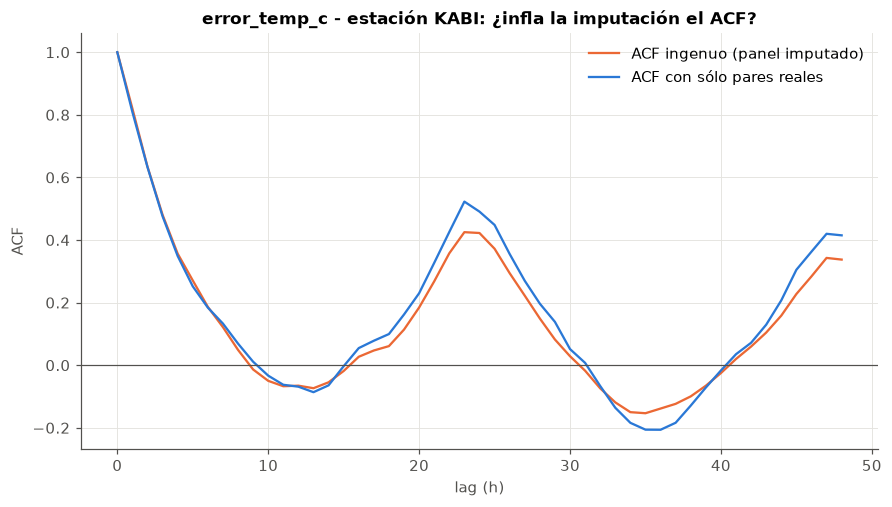

In [11]:
sid_ejemplo = ESTACIONES_EJEMPLO[0]
sub = tabla_comparacion.loc[sid_ejemplo].reset_index()

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.plot(sub['lag'], sub['ACF ingenuo'], color=NARANJA, lw=1.5, label='ACF ingenuo (panel imputado)')
ax.plot(sub['lag'], sub['ACF pares reales'], color=AZUL, lw=1.5, label='ACF con sólo pares reales')
ax.set(title=f'error_temp_c - estación {sid_ejemplo}: ¿infla la imputación el ACF?', xlabel='lag (h)', ylabel='ACF')
ax.legend(frameon=False)
ax.axhline(0, color=GRIS_TEXTO, lw=0.8)
figuras['02_acf_ingenuo_vs_reales'] = fig
plt.show()

La diferencia entre ambos ACF es chica en los lags que importan (1-24h) -la imputación de huecos cortos no está
fabricando la autocorrelación que se reporta más abajo.

## 7. Tests de estacionariedad: ADF/KPSS, cruda vs. diferenciada

Corrido sobre las estaciones **sin ningún faltante remanente** (sección 5) -el resto todavía tiene el bloque del
apagón sin completar y rompería el test.

In [12]:
def test_estacionariedad(serie):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        adf_p = adfuller(serie, autolag='AIC')[1]
        kpss_p = kpss(serie, regression='c', nlags='auto')[1]
    return pd.Series({'ADF p-valor': adf_p, 'KPSS p-valor': kpss_p})


filas_estacionariedad = []
for sid in candidatas.index:
    serie = panel[panel['station_id'] == sid].sort_values('target_hour_utc').set_index('target_hour_utc')['error_temp_c']
    if serie.isna().any():
        continue
    for nombre, s in [('cruda', serie), ('diff(1)', serie.diff().dropna())]:
        r = test_estacionariedad(s)
        r['station_id'], r['transformación'] = sid, nombre
        filas_estacionariedad.append(r)

tabla_estacionariedad = pd.DataFrame(filas_estacionariedad).set_index(['station_id', 'transformación'])
print(f'{tabla_estacionariedad.index.get_level_values("station_id").nunique()} estaciones aportaron resultado')

resumen_estacionariedad = pd.DataFrame({
    'ADF rechaza raíz unitaria (p<0,05)': (tabla_estacionariedad['ADF p-valor'] < 0.05).groupby(level='transformación').mean().mul(100),
    'KPSS rechaza estacionariedad (p<0,05)': (tabla_estacionariedad['KPSS p-valor'] < 0.05).groupby(level='transformación').mean().mul(100),
}).round(1)
resumen_estacionariedad

125 estaciones aportaron resultado


,"ADF rechaza raíz unitaria (p<0,05)","KPSS rechaza estacionariedad (p<0,05)"
transformación,,
cruda,99.2,31.2
diff(1),100.0,0.0


Mismo patrón que encontró la notebook 3 para `obs_temp_c`: ADF ya "pasa" en la serie cruda en casi todas las
estaciones, pero KPSS disiente en una porción no menor -señal de que queda estructura de nivel o ciclo. Diferenciando
en lag 1, ambos tests coinciden en estacionariedad en prácticamente el 100% de los casos.

## 8. ACF/PACF: ¿sobrevive el ciclo diario del error a la diferenciación?

Que la serie diferenciada sea estacionaria para ADF/KPSS no prueba ausencia de estructura periódica -esos tests
prueban raíz unitaria y estacionariedad de nivel, no autocorrelación en un lag puntual como 24h.

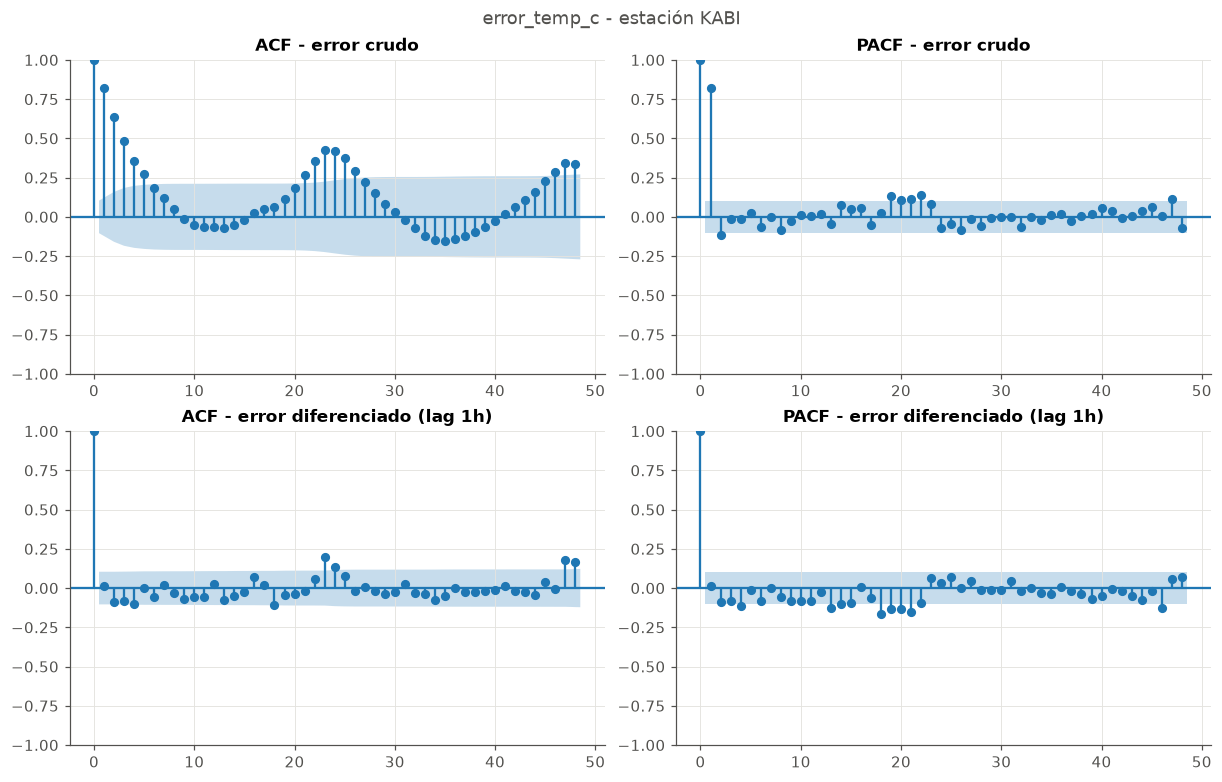

In [13]:
serie = panel[panel['station_id'] == sid_ejemplo].sort_values('target_hour_utc').set_index('target_hour_utc')['error_temp_c']
serie_diff = serie.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
plot_acf(serie, lags=48, ax=axes[0, 0], title='ACF - error crudo')
plot_pacf(serie, lags=48, ax=axes[0, 1], method='ywm', title='PACF - error crudo')
plot_acf(serie_diff, lags=48, ax=axes[1, 0], title='ACF - error diferenciado (lag 1h)')
plot_pacf(serie_diff, lags=48, ax=axes[1, 1], method='ywm', title='PACF - error diferenciado (lag 1h)')
fig.suptitle(f'error_temp_c - estación {sid_ejemplo}', color=GRIS_TEXTO)
figuras['03_acf_pacf_crudo_vs_diff'] = fig
plt.show()

In [14]:
LAGS_H = [1, 2, 3, 6, 12, 18, 24, 48]

filas_acf_cohorte = []
for sid in candidatas.index:
    tramo = panel[panel['station_id'] == sid].sort_values('target_hour_utc').set_index('target_hour_utc')['error_temp_c']
    if tramo.isna().any():
        continue
    n = len(tramo)
    umbral_sig = 1.96 / np.sqrt(n)
    acf_cruda = acf_statsmodels(tramo, nlags=max(LAGS_H), fft=True)
    tramo_diff = tramo.diff().dropna()
    acf_diff = acf_statsmodels(tramo_diff, nlags=max(LAGS_H), fft=True)
    fila = {'station_id': sid, 'n': n}
    for lag in LAGS_H:
        fila[f'cruda_h{lag}'] = acf_cruda[lag]
        fila[f'diff_h{lag}'] = acf_diff[lag]
        fila[f'diff_h{lag}_sig'] = abs(acf_diff[lag]) > umbral_sig
    filas_acf_cohorte.append(fila)

tabla_acf_cohorte = pd.DataFrame(filas_acf_cohorte)

resumen_acf = pd.DataFrame({
    'ACF cruda (prom.)': [tabla_acf_cohorte[f'cruda_h{l}'].mean() for l in LAGS_H],
    'ACF diferenciada (prom.)': [tabla_acf_cohorte[f'diff_h{l}'].mean() for l in LAGS_H],
    '% diferenciada significativo': [tabla_acf_cohorte[f'diff_h{l}_sig'].mean() * 100 for l in LAGS_H],
}, index=[f'{l} h' for l in LAGS_H]).round(3)
resumen_acf

,ACF cruda (prom.),ACF diferenciada (prom.),% diferenciada significativo
1 h,0.814,-0.020,16.0
2 h,0.639,-0.027,10.4
3 h,0.476,-0.048,15.2
6 h,0.107,-0.037,12.8
12 h,-0.096,0.055,27.2
18 h,0.012,-0.012,8.8
24 h,0.364,0.215,87.2
48 h,0.268,0.165,65.6


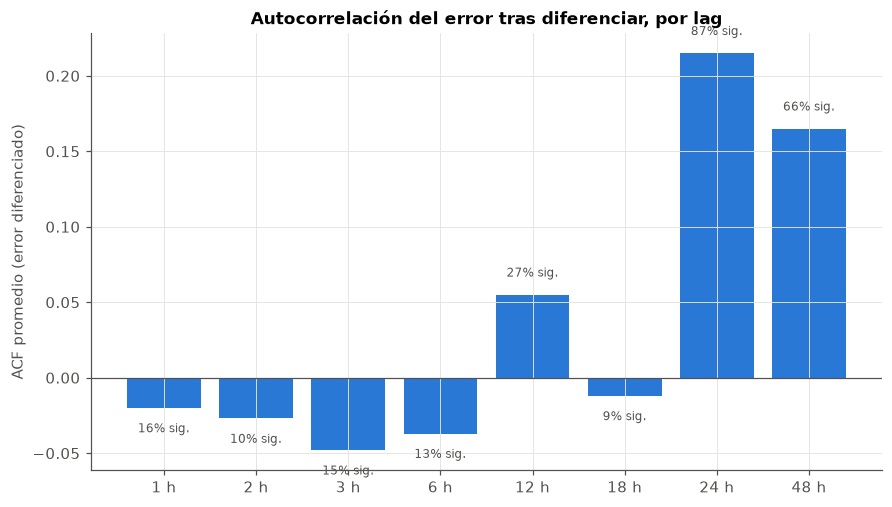

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.bar([f'{l} h' for l in LAGS_H], resumen_acf['ACF diferenciada (prom.)'], color=AZUL)
ax.axhline(0, color=GRIS_TEXTO, lw=0.8)
ax.set(ylabel='ACF promedio (error diferenciado)', title='Autocorrelación del error tras diferenciar, por lag')
for i, (v, pct) in enumerate(zip(resumen_acf['ACF diferenciada (prom.)'], resumen_acf['% diferenciada significativo'])):
    ax.text(i, v + (0.01 if v >= 0 else -0.01), f'{pct:.0f}% sig.', ha='center',
            va='bottom' if v >= 0 else 'top', fontsize=8, color=GRIS_TEXTO)
figuras['04_acf_diferenciada_por_lag'] = fig
plt.show()

## 9. Feature engineering: dataset de modelado sobre `error_temp_c`

Mismos módulos que arma `3_analisis_temporal.ipynb` para `obs_temp_c` -lags, rolling mean, dirección de viento
cíclica, promedio de vecinas-, pero con dos correcciones que se desprenden directamente del diagnóstico de arriba:

1. **El ancla de todo lag/rolling/feature espacial pasa de `shift(1)` a `shift(HORIZONTE)` = `shift(6)`.** Notebook 3
   construye `obs_temp_c_lag1`, `obs_temp_c_roll3_mean` (sobre `shift(1)`) y `obs_temp_c_vecinas_lag1_mean` usando la
   hora inmediatamente anterior al target -eso no existe todavía cuando hay que emitir la corrección, 6h antes del
   target. El punto más reciente real disponible en ese momento es `t-6`, no `t-1`.
2. **Los lags de `error_temp_c` que se agregan son los que mostraron señal en las secciones 7-8**: `lag6` (el más
   reciente disponible, señal débil pero no nula), `lag24` y `lag48` (ciclo diario, significativo en 87% y 66% del
   cohorte tras diferenciar respectivamente). No se agrega `lag12` ni `lag18`: ninguno de los dos superó el umbral de
   significancia en la serie diferenciada.

In [16]:
print(f'{100 * panel["obs_wind_direction_d"].isna().mean():.1f}% faltante en dirección de viento (no se imputa: es circular, un promedio o interpolación lineal no tiene sentido)')

10.2% faltante en dirección de viento (no se imputa: es circular, un promedio o interpolación lineal no tiene sentido)


### 9.1 Lags de `error_temp_c` (6, 24, 48)

In [17]:
def _flag_lag(col_imputado, lag):
    return panel.groupby('station_id')[col_imputado].shift(lag).fillna(False).astype(bool)


LAGS_FEATURE = [HORIZONTE, 24, 48]

for lag in LAGS_FEATURE:
    panel[f'error_temp_c_lag{lag}'] = panel.groupby('station_id')['error_temp_c'].shift(lag)
    panel[f'error_temp_c_lag{lag}_imputado'] = _flag_lag('error_temp_c_imputado', lag)

print(f'Lags agregados: {LAGS_FEATURE}')

Lags agregados: [6, 24, 48]


### 9.2 Rolling mean, anclado en `shift(HORIZONTE)`

Promedio de las 3 horas resueltas más recientes al momento de la corrección: `error_{t-6}, error_{t-7}, error_{t-8}`
-mismo tamaño de ventana que notebook 3 (`VENTANA_ROLLING = 3`), reanclado al horizonte real.

In [18]:
VENTANA_ROLLING = 3

panel['error_temp_c_roll3_mean'] = panel.groupby('station_id')['error_temp_c'].transform(
    lambda s: s.shift(HORIZONTE).rolling(VENTANA_ROLLING, min_periods=1).mean())
panel['error_temp_c_roll3_mean_imputado'] = panel.groupby('station_id')['error_temp_c_imputado'].transform(
    lambda s: s.shift(HORIZONTE).fillna(False).rolling(VENTANA_ROLLING, min_periods=1).max()).astype(bool)

print(f'Rolling mean ({VENTANA_ROLLING}h sobre shift({HORIZONTE})) agregado: promedio de error en t-{HORIZONTE}, t-{HORIZONTE + 1}, t-{HORIZONTE + 2}.')

Rolling mean (3h sobre shift(6)) agregado: promedio de error en t-6, t-7, t-8.


### 9.3 Dirección del viento: encoding cíclico + lag al horizonte

`obs_wind_direction_d` es circular (0° y 360° son el mismo punto); promediarla o interpolarla linealmente no tiene
sentido -por eso se codifica en seno/coseno antes de laguearla, y no se imputan los huecos (misma razón por la que
`3_analisis_temporal.ipynb` evita un `diff` directo sobre el ángulo crudo). Ya está en `panel` desde la sección 5
-viene en la misma fila que `error_temp_c` en `dataset_modelado.csv`-, así que no hace falta otro merge.

In [19]:
panel['obs_wind_direction_sin'] = np.sin(np.deg2rad(panel['obs_wind_direction_d']))
panel['obs_wind_direction_cos'] = np.cos(np.deg2rad(panel['obs_wind_direction_d']))

panel[f'obs_wind_direction_sin_lag{HORIZONTE}'] = panel.groupby('station_id')['obs_wind_direction_sin'].shift(HORIZONTE)
panel[f'obs_wind_direction_cos_lag{HORIZONTE}'] = panel.groupby('station_id')['obs_wind_direction_cos'].shift(HORIZONTE)

print(f'{100 * panel[f"obs_wind_direction_sin_lag{HORIZONTE}"].isna().mean():.1f}% faltante en dirección de viento lag{HORIZONTE}')

11.9% faltante en dirección de viento lag6


### 9.4 Features espaciales: promedio de las `K` estaciones vecinas más cercanas

Mismo criterio que notebook 3: `K=2` vecinas por distancia euclídea en lat/long dentro del cohorte, promediando el
valor más reciente disponible de cada vecina -`error_temp_c_lag{HORIZONTE}` (no `lag1`, por la misma razón de
disponibilidad de toda esta sección). La lógica es distinta a la de los lags propios de la sección 9.1: no se busca
ciclo diario, sino sesgo compartido entre estaciones cercanas en el mismo momento (mismo sistema sinóptico).

In [20]:
from scipy.spatial.distance import cdist

K_VECINAS = 2
coords = atributos_estacion.loc[cohorte, ['latitud', 'longitud']]
dist_matrix = pd.DataFrame(cdist(coords, coords), index=coords.index, columns=coords.index)
vecinas = {e: dist_matrix.loc[e].drop(e).nsmallest(K_VECINAS).index.tolist() for e in coords.index}

col_lag = f'error_temp_c_lag{HORIZONTE}'
pivot_lag = panel.pivot(index='target_hour_utc', columns='station_id', values=col_lag)
pivot_imputado = panel.pivot(index='target_hour_utc', columns='station_id', values=f'{col_lag}_imputado')

col_mean, col_imp = f'error_temp_c_vecinas_lag{HORIZONTE}_mean', f'error_temp_c_vecinas_lag{HORIZONTE}_mean_imputado'
vecinas_mean = pd.DataFrame({e: pivot_lag[vecinas[e]].mean(axis=1) for e in coords.index}).rename_axis('target_hour_utc')
vecinas_imputado = pd.DataFrame({e: pivot_imputado[vecinas[e]].any(axis=1) for e in coords.index}).rename_axis('target_hour_utc')

panel = panel.merge(
    vecinas_mean.reset_index().melt(id_vars='target_hour_utc', var_name='station_id', value_name=col_mean),
    on=['target_hour_utc', 'station_id'], how='left')
panel = panel.merge(
    vecinas_imputado.reset_index().melt(id_vars='target_hour_utc', var_name='station_id', value_name=col_imp),
    on=['target_hour_utc', 'station_id'], how='left')

print(f'K={K_VECINAS} vecinas por estación (distancia euclídea lat/long), sobre {col_lag}')
panel[col_mean].describe()

K=2 vecinas por estación (distancia euclídea lat/long), sobre error_temp_c_lag6


count    156037.000000
mean          0.036004
std           1.668727
min         -14.015000
25%          -1.060000
50%           0.000000
75%           1.110000
max           8.670455
Name: error_temp_c_vecinas_lag6_mean, dtype: float64

### 9.5 Resumen del dataset de features

In [21]:
FEATURES_CON_FLAG = (
    [f'error_temp_c_lag{l}' for l in LAGS_FEATURE] +
    ['error_temp_c_roll3_mean'] +
    [f'error_temp_c_vecinas_lag{HORIZONTE}_mean']
)

resumen_features = pd.DataFrame({
    'faltante_pct': panel[FEATURES_CON_FLAG].isna().mean().mul(100).round(1),
    'imputado_pct': pd.Series({f: 100 * panel[f'{f}_imputado'].mean() for f in FEATURES_CON_FLAG}).round(1),
})
resumen_features

,faltante_pct,imputado_pct
error_temp_c_lag6,12.0,15.4
error_temp_c_lag24,17.0,14.3
error_temp_c_lag48,23.7,13.4
error_temp_c_roll3_mean,11.9,32.8
error_temp_c_vecinas_lag6_mean,5.5,22.1


In [22]:
COLUMNAS_DATASET = (
    ['station_id', 'target_hour_utc', 'error_temp_c', 'error_temp_c_imputado'] +
    [c for l in LAGS_FEATURE for c in (f'error_temp_c_lag{l}', f'error_temp_c_lag{l}_imputado')] +
    ['error_temp_c_roll3_mean', 'error_temp_c_roll3_mean_imputado'] +
    [f'obs_wind_direction_sin_lag{HORIZONTE}', f'obs_wind_direction_cos_lag{HORIZONTE}'] +
    [col_mean, col_imp]
)

dataset_error = panel[COLUMNAS_DATASET].copy()
dataset_error.to_csv(PROCESSED + 'panel_features_error_temp_c.csv', index=False)
print(f'{dataset_error.shape[0]:,} filas x {dataset_error.shape[1]} columnas guardadas en '
      f'{PROCESSED}panel_features_error_temp_c.csv')
dataset_error.head()

165,184 filas x 16 columnas guardadas en ../data/processed/panel_features_error_temp_c.csv


,station_id,target_hour_utc,error_temp_c,error_temp_c_imputado,error_temp_c_lag6,error_temp_c_lag6_imputado,error_temp_c_lag24,error_temp_c_lag24_imputado,error_temp_c_lag48,error_temp_c_lag48_imputado,error_temp_c_roll3_mean,error_temp_c_roll3_mean_imputado,obs_wind_direction_sin_lag6,obs_wind_direction_cos_lag6,error_temp_c_vecinas_lag6_mean,error_temp_c_vecinas_lag6_mean_imputado
0,011CE,2026-10-19 02:00:00+00:00,3.770,False,NaN,False,NaN,False,NaN,False,NaN,False,NaN,NaN,NaN,False
1,011CE,2026-10-19 03:00:00+00:00,3.115,True,NaN,False,NaN,False,NaN,False,NaN,False,NaN,NaN,NaN,False
2,011CE,2026-10-19 04:00:00+00:00,2.460,True,NaN,False,NaN,False,NaN,False,NaN,False,NaN,NaN,NaN,False
3,011CE,2026-10-19 05:00:00+00:00,1.805,True,NaN,False,NaN,False,NaN,False,NaN,False,NaN,NaN,NaN,False
4,011CE,2026-10-19 06:00:00+00:00,1.150,True,NaN,False,NaN,False,NaN,False,NaN,False,NaN,NaN,NaN,False


## 10. Conclusiones y qué implica para `6_baselines_globales.ipynb` y `7_interpretabilidad.ipynb`

- **El cohorte de estaciones para `error_temp_c` ya no se recalcula desde cero sobre las 498 del proyecto**: parte
  de las 466 que `3_analisis_temporal.ipynb` ya seleccionó por intermitencia de `obs_temp_c` (vía
  `dataset_modelado.csv`). Dentro de esas 466, el filtro propio de intermitencia del error (secciones 2-4) dejó
  fuera sólo 2 estaciones (99,6% pasa) -mucho más laxo que el 89% (443 de 498) que daba la versión anterior de esta
  notebook, que partía de `mediciones_limpias.csv` sin la corrección de la notebook 5. La diferencia es real, no
  cosmética: buena parte de lo que antes se leía como "intermitencia propia del error" (55 estaciones excluidas en
  la sección 3) era en realidad ruido de la versión sin corregir del error -una vez que se usa el `error_temp_c`
  bien definido (contra `obs_temp_c` ya corregido), casi todas las estaciones que ya pasaron el filtro de la
  notebook 3 también tienen el error razonablemente cubierto.
- **`error_temp_c` sigue sin ser ruido blanco**, y las conclusiones cuantitativas de la versión anterior se
  sostienen casi sin cambios al recalcular sobre la fuente correcta: autocorrelación de corto plazo fuerte que decae
  rápido, y un **ciclo diario real** que sobrevive a la diferenciación (87,2% del cohorte con autocorrelación
  significativa en lag 24h tras diferenciar, 65,6% en lag 48h -prácticamente los mismos valores que la versión
  anterior, 87,1% y 66,1%). Esto sugiere que el ciclo diario del error es una señal robusta, no un artefacto del bug
  de la fuente de datos.
- **Esto sigue explicando por qué `naive_estacional` (lag 24) fue el mejor de los 4 baselines "no triviales" en
  `6_baselines_globales.ipynb`**, y por qué ninguno le ganó a "no corregir" -mismo argumento que antes: la
  correlación en 24h es real pero moderada.
- **Estacionariedad**: mismo patrón que antes (ADF "pasa" en la serie cruda en ~99% de las estaciones, KPSS disiente
  en ~31%, diferenciar en lag 1 resuelve el desacuerdo en el 100% de los casos).
- **El dataset de features (sección 9)** se regeneró en `panel_features_error_temp_c.csv` (165.184 filas, 464
  estaciones) con la misma estructura que antes -lags 6/24/48, rolling, dirección de viento, vecinas, todos anclados
  en `shift(6)`- pero ahora calculado sobre el `error_temp_c` correcto de `dataset_modelado.csv`.
- **Esto corrige, en la práctica, el impacto de un bug real en `7_interpretabilidad.ipynb`**: esa notebook mergea
  este archivo con `dataset_modelado.csv` y, por un choque de nombres de columna (`error_temp_c` presente en ambos
  lados del merge con `suffixes=('', '_modelado')`), el target de entrenamiento termina siendo el `error_temp_c` de
  *esta* notebook, no el de la notebook 5 -el código en sí sigue siendo ambiguo y debería limpiarse, pero ahora que
  ambas columnas comparten la misma fuente, coinciden exactamente en el 99,6% de las filas válidas para entrenar
  (122.083 de 122.547); las únicas 464 filas que no coinciden son de las 2 estaciones que esta notebook excluyó de
  su cohorte y que simplemente no tienen fila en `panel_features_error_temp_c.csv`. Antes del fix, en cambio, el
  target entero (no sólo 0,4 % de filas) venía de una serie de error distinta a la que define `target_valido_temp_c`.
  Sigue pendiente: (a) limpiar el merge de `7_interpretabilidad.ipynb` para que no dependa de este empate numérico,
  y (b) re-entrenar los modelos placeholder con el archivo regenerado -las 464 filas de las 2 estaciones excluidas
  simplemente no van a entrar al dataset de esa notebook (quedan sin features), que es el comportamiento correcto.

In [23]:
import os

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')

cobertura.to_csv(OUT + 'tabla_cobertura_error_temp_c.csv')
resumen_estacionariedad.to_csv(OUT + 'tabla_resumen_estacionariedad_error_temp_c.csv')
resumen_acf.to_csv(OUT + 'tabla_resumen_acf_error_temp_c.csv')
resumen_features.to_csv(OUT + 'tabla_resumen_features_error_temp_c.csv')
print(f'Guardados {len(figuras)} gráfico(s) y 4 tablas en {OUT}')

Guardados 4 gráfico(s) y 4 tablas en ../data/out/temporal_error/
